# Shoplifting V6 — No Attention (V5 Architecture Ablation)
Standalone from original videos. Same V5 settings and 85/15 train/test by exact V5 SHA-256 hashes. Only Attention pooling is replaced by masked mean pooling.


In [1]:
# 1 — Colab + essentials
from pathlib import Path
from functools import lru_cache
from contextlib import nullcontext
import os, re, time, json, hashlib, random
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageEnhance
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Colab not detected; set DATA_ROOT below to your local raw-video folder.')

# Only edit DATA_ROOT if your original videos are elsewhere.
DATA_ROOT = Path('/content/drive/MyDrive/Cellula/Shoplifting-Detection/DataSet')
V5_DIR = DATA_ROOT / 'shoplifting_independent_v5_train_test'
V5_SPLIT_PATH = V5_DIR / 'video_split.csv'
assert V5_SPLIT_PATH.is_file(), f'Need V5 split to ensure identical train/test videos: {V5_SPLIT_PATH}'
OUT = DATA_ROOT / 'shoplifting_independent_v6_no_attention'
FRAME_DIR = OUT / 'frames_1fps'
OUT.mkdir(parents=True, exist_ok=True)
FRAME_DIR.mkdir(parents=True, exist_ok=True)

# Main hyperparameters
SEED = 42
EPOCHS = 30  # Matches executed Original V5 (not fine-tuned)
BATCH_SIZE = 8  # Matches executed Original V5
LEARNING_RATE = 1e-3
FLIP_PROB = 0.50
COLOR_JITTER = 0.15

# Keep 1 FPS and augmentation exactly identical to V5; remove only Attention.
SAMPLE_FPS = 1.0
IMAGE_SIZE = 112
CNN_CHUNK_SIZE = 24

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE, '| Raw videos:', DATA_ROOT)
if DEVICE.type == 'cpu':
    print('For faster training in Colab: Runtime > Change runtime type > T4 GPU.')
assert DATA_ROOT.is_dir(), 'Raw video folder not found. Set DATA_ROOT to your original MP4 folder.'

Mounted at /content/drive
Device: cuda | Raw videos: /content/drive/MyDrive/Cellula/Shoplifting-Detection/DataSet


In [2]:
# 2 — Find ORIGINAL videos and their labels, without reading previous CSVs.
VIDEO_EXTENSIONS = {'.mp4', '.avi', '.mov', '.mkv'}
NORMAL_DIRS = {'non shop lifters', 'non shop lifter', 'normal', 'non shoplifting', 'non shoplifters'}
THEFT_DIRS = {'shop lifters', 'shop lifter', 'shoplifting', 'shoplifters', 'theft'}

def class_from_folders(path):
    parts = [re.sub(r'[^a-z0-9]+', ' ', x.lower()).strip()
             for x in path.relative_to(DATA_ROOT).parent.parts]
    if any(p in NORMAL_DIRS for p in parts):
        return 0
    if any(p in THEFT_DIRS for p in parts):
        return 1
    return None

records = []
for path in DATA_ROOT.rglob('*'):
    if not path.is_file() or path.suffix.lower() not in VIDEO_EXTENSIONS:
        continue
    if OUT in path.parents:
        continue
    label = class_from_folders(path)
    if label is None:  # e.g. experiment outputs outside the original class folders
        continue
    records.append({
        'relative_path': path.relative_to(DATA_ROOT).as_posix(),
        'video_path': str(path.resolve()),
        'class_name': ('Normal' if label == 0 else 'Shoplifting'),
        'label': label,
        'size_bytes': path.stat().st_size,
    })
raw = pd.DataFrame(records)
assert not raw.empty, 'No labeled videos found. Expect folders such as "shop lifters" and "non shop lifters".'
assert raw.relative_path.is_unique
print('Raw video files:', len(raw))
print(raw.class_name.value_counts().to_string())
raw.to_csv(OUT / 'raw_inventory.csv', index=False)

Raw video files: 855
class_name
Normal         531
Shoplifting    324


In [3]:
# 3 — Same cleaned videos. Train=85%, Test=15%, no validation.
# To compare fairly with V3, use exactly the same test video identities when available.
def sha256_file(path):
    h = hashlib.sha256()
    with open(path, 'rb') as handle:
        for block in iter(lambda: handle.read(4 * 1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

raw['sha256'] = [sha256_file(p) for p in tqdm(raw.video_path, desc='Hash videos')]
assert raw.groupby('sha256').label.nunique().le(1).all(), 'Conflicting exact-duplicate labels.'
unique = raw.drop_duplicates('sha256').copy()
print('Exact duplicates removed:', len(raw) - len(unique))

# Same five known overlap exclusions as V3.
KNOWN_OVERLAP_PAIRS = [
    ('shop lifters/shop_lifter_103.mp4', 'shop lifters/shop_lifter_86.mp4'),
    ('non shop lifters/shop_lifter_n_84.mp4', 'non shop lifters/shop_lifter_n_89.mp4'),
    ('non shop lifters/videppppsss_36.mp4', 'non shop lifters/videppppsss_37.mp4'),
    ('non shop lifters/shop_lifter_n_82.mp4', 'non shop lifters/shop_lifter_n_86.mp4'),
    ('shop lifters/shop_lifter_102.mp4', 'shop lifters/shop_lifter_85.mp4'),
]
path_map = {x.lower(): x for x in unique.relative_path}
remove_paths = set()
for first, second in KNOWN_OVERLAP_PAIRS:
    a, b = path_map.get(first.lower()), path_map.get(second.lower())
    if a is not None and b is not None:
        la = int(unique.loc[unique.relative_path == a, 'label'].iloc[0])
        lb = int(unique.loc[unique.relative_path == b, 'label'].iloc[0])
        assert la == lb, f'Conflicting overlap labels: {a} / {b}'
        remove_paths.add(b)
unique = unique.loc[~unique.relative_path.isin(remove_paths)].reset_index(drop=True)
print('Known overlaps removed:', len(remove_paths))

# Controlled V5 vs V6 comparison: LOCK BOTH TRAIN AND TEST memberships by SHA-256.
# Uses V5 only for split membership; video frames come exclusively from original videos.
v5_split = pd.read_csv(V5_SPLIT_PATH)
needed_cols = {'sha256', 'split', 'label'}
assert needed_cols.issubset(v5_split.columns), f'V5 split missing {needed_cols - set(v5_split.columns)}'
assert v5_split.sha256.is_unique, 'V5 split contains duplicate hashes'
assert set(v5_split.split) == {'train', 'test'}, 'Unexpected V5 split values'
assert set(v5_split.sha256.astype(str)) == set(unique.sha256.astype(str)), (
    'V5 and V6 video hashes differ. Stop: cannot make a controlled comparison.'
)
label_lookup = dict(zip(unique.sha256.astype(str), unique.label.astype(int)))
assert all(label_lookup[str(r.sha256)] == int(r.label) for r in v5_split.itertuples(index=False)), (
    'Labels disagree with V5 split'
)
# Preserve V5 manifest ordering so shuffled training input order is as comparable as possible.
ordered_unique = unique.set_index('sha256').loc[v5_split.sha256.astype(str)].reset_index()
ordered_unique['split'] = v5_split.split.to_numpy()
manifest = ordered_unique.copy()
train = manifest.loc[manifest.split == 'train'].copy()
test = manifest.loc[manifest.split == 'test'].copy()
assert len(test) == 95, f'Expected V5 test of 95 videos; got {len(test)}'
print('LOCKED train/test to the exact V5 hashes and ordering.')

assert set(train.sha256).isdisjoint(set(test.sha256))
assert len(train) + len(test) == len(unique)
assert train.label.nunique() == 2 and test.label.nunique() == 2
manifest.to_csv(OUT / 'video_split.csv', index=False)
print(pd.crosstab(manifest.split, manifest.class_name).to_string())
print('No validation set. Test must NOT be used to select epochs or learning rate.')
print('Caution: unknown overlapping sessions may still cause train/test leakage.')


Hash videos:   0%|          | 0/855 [00:00<?, ?it/s]

Exact duplicates removed: 218
Known overlaps removed: 5
LOCKED train/test to the exact V5 hashes and ordering.
class_name  Normal  Shoplifting
split                          
test            47           48
train          263          274
No validation set. Test must NOT be used to select epochs or learning rate.
Caution: unknown overlapping sessions may still cause train/test leakage.


In [4]:
# 4 — Preprocess ORIGINAL videos into RGB frames sampled at 1 FPS.
# New cache is generated here, not reused from V5 or other experiments.
def sample_video_1fps(path):
    cap = cv2.VideoCapture(str(path))
    if not cap.isOpened():
        raise RuntimeError(f'Cannot open: {path}')
    try:
        fps = float(cap.get(cv2.CAP_PROP_FPS))
        n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        if not (np.isfinite(fps) and 1 <= fps <= 240 and n > 0):
            raise ValueError(f'Invalid video FPS/frame count: {path} | {fps}, {n}')
        ids = np.unique(np.rint(np.arange(0, n / fps, 1.0 / SAMPLE_FPS) * fps).astype(int))
        ids = ids[(ids >= 0) & (ids < n)]
        frames = []
        for idx in ids:
            cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
            ok, bgr = cap.read()
            if not ok or bgr is None:
                raise RuntimeError(f'Cannot decode {path} at frame {idx}')
            rgb = cv2.cvtColor(cv2.resize(bgr, (IMAGE_SIZE, IMAGE_SIZE),
                                                interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2RGB)
            frames.append(rgb)
        return np.stack(frames).astype(np.uint8), fps, n
    finally:
        cap.release()

cache_paths, sampled_counts, fps_values, original_counts = [], [], [], []
for row in tqdm(manifest.itertuples(index=False), total=len(manifest), desc='Prepare V6 1-FPS RGB clips'):
    dst = FRAME_DIR / f'{row.sha256[:20]}_{IMAGE_SIZE}_{int(SAMPLE_FPS)}fps.npy'
    if dst.is_file():
        arr = np.load(dst, mmap_mode='r', allow_pickle=False)
        if arr.ndim != 4 or arr.shape[1:] != (IMAGE_SIZE, IMAGE_SIZE, 3) or arr.dtype != np.uint8:
            raise RuntimeError(f'Invalid cached clip: {dst}')
        count = len(arr)
        cap = cv2.VideoCapture(row.video_path)
        fps = float(cap.get(cv2.CAP_PROP_FPS))
        n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        cap.release()
    else:
        arr, fps, n = sample_video_1fps(row.video_path)
        np.save(dst, arr, allow_pickle=False)
        count = len(arr)
    assert count > 0
    cache_paths.append(str(dst))
    sampled_counts.append(count)
    fps_values.append(fps)
    original_counts.append(n)
manifest['cache_path'] = cache_paths
manifest['sampled_frames'] = sampled_counts
manifest['fps'] = fps_values
manifest['original_frame_count'] = original_counts
manifest.to_csv(OUT / 'video_split.csv', index=False)
print('Ready:', len(manifest), 'videos | Total sampled frames:', sum(sampled_counts))
print('Frames/clip min, median, max:', min(sampled_counts), int(np.median(sampled_counts)), max(sampled_counts))

Prepare V6 1-FPS RGB clips:   0%|          | 0/632 [00:00<?, ?it/s]

Ready: 632 videos | Total sampled frames: 8289
Frames/clip min, median, max: 3 13 74


In [5]:
# 5 — Dataset. ONE flip decision + ONE set of color factors for the ENTIRE video.
@lru_cache(maxsize=800)
def read_clip(path):
    return np.load(path, allow_pickle=False)

def augment_clip(rgb, flip=None, brightness=None, contrast=None, saturation=None):
    flip = (random.random() < FLIP_PROB) if flip is None else flip
    brightness = random.uniform(1-COLOR_JITTER, 1+COLOR_JITTER) if brightness is None else brightness
    contrast = random.uniform(1-COLOR_JITTER, 1+COLOR_JITTER) if contrast is None else contrast
    saturation = random.uniform(1-COLOR_JITTER, 1+COLOR_JITTER) if saturation is None else saturation
    if flip:
        rgb = rgb[:, :, ::-1, :]
    result = []
    for frame in rgb:  # Factors don't change inside this loop.
        image = Image.fromarray(np.ascontiguousarray(frame))
        image = ImageEnhance.Brightness(image).enhance(brightness)
        image = ImageEnhance.Contrast(image).enhance(contrast)
        image = ImageEnhance.Color(image).enhance(saturation)
        result.append(np.asarray(image, dtype=np.uint8))
    return np.stack(result)

class VideoDataset(Dataset):
    def __init__(self, rows, train_mode=False):
        self.rows = rows.reset_index(drop=True)
        self.train_mode = train_mode
    def __len__(self):
        return len(self.rows)
    def __getitem__(self, i):
        r = self.rows.iloc[i]
        rgb = read_clip(r.cache_path)
        if self.train_mode:
            rgb = augment_clip(rgb)
        x = torch.from_numpy(np.ascontiguousarray(rgb)).permute(0, 3, 1, 2).float() / 255.0
        return (x - 0.5) / 0.5, int(r.label)

def collate(batch):
    xs, ys = zip(*batch)
    lengths = torch.tensor([len(x) for x in xs], dtype=torch.long)
    return pad_sequence(xs, batch_first=True), torch.tensor(ys, dtype=torch.long), lengths

train_ds = VideoDataset(manifest[manifest.split == 'train'], train_mode=True)
test_ds = VideoDataset(manifest[manifest.split == 'test'])
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate, num_workers=0)
x, label = train_ds[0]
assert x.ndim == 4 and x.shape[1:] == (3, IMAGE_SIZE, IMAGE_SIZE)
print('Sample tensor:', tuple(x.shape), '| Label:', label)
print('Videos Train/Test:', len(train_ds), len(test_ds))

Sample tensor: (10, 3, 112, 112) | Label: 0
Videos Train/Test: 537 95


Consistent augmentation: PASS | Horizontal flip direction: PASS


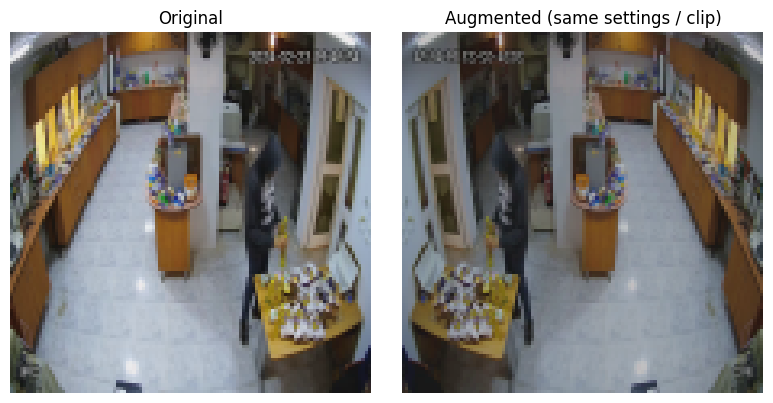

In [6]:
# 6 — Visual and code checks: identical frames -> identical augmentation.
source_frames = read_clip(train_ds.rows.iloc[0].cache_path)
repeated = np.repeat(source_frames[:1], 4, axis=0)
check = augment_clip(repeated)
assert np.array_equal(check[0], check[1]) and np.array_equal(check[0], check[3])
# Horizontal flip must move right pixels to left, identically for every frame.
flipped = augment_clip(repeated, flip=True, brightness=1., contrast=1., saturation=1.)
assert np.array_equal(flipped, repeated[:, :, ::-1, :])
print('Consistent augmentation: PASS | Horizontal flip direction: PASS')
preview = augment_clip(source_frames)
i = len(source_frames) // 2
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(source_frames[i]); ax[0].set_title('Original')
ax[1].imshow(preview[i]); ax[1].set_title('Augmented (same settings / clip)')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()

In [7]:
# 7 — CNN + BiLSTM (NO ATTENTION). Same CNN/LSTM/classifier sizes as V5.
# Replace attention-weighted pooling with masked temporal MEAN; keep MAX branch.
class SpatialBlock(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(cin, cout, 3, stride=2, padding=1, bias=False),
            nn.GroupNorm(8, cout), nn.SiLU(inplace=True),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False),
            nn.GroupNorm(8, cout), nn.SiLU(inplace=True))
    def forward(self, x):
        return self.net(x)

class Original1FPSCNNBiLSTMNoAttention(nn.Module):
    def __init__(self, cnn_chunk_size=24):
        super().__init__()
        self.cnn_chunk_size = cnn_chunk_size
        self.cnn = nn.Sequential(SpatialBlock(3, 24), SpatialBlock(24, 48),
                                 SpatialBlock(48, 96), SpatialBlock(96, 160),
                                 nn.AdaptiveAvgPool2d((2, 2)))
        self.project = nn.Sequential(nn.Flatten(), nn.Linear(160*2*2, 160),
                                     nn.LayerNorm(160), nn.SiLU(), nn.Dropout(0.1))
        self.lstm = nn.LSTM(160, 128, batch_first=True, bidirectional=True)
        self.classifier = nn.Sequential(nn.LayerNorm(512), nn.Dropout(0.30),
                                        nn.Linear(512, 128), nn.SiLU(),
                                        nn.Dropout(0.15), nn.Linear(128, 2))
    def forward(self, video, lengths):
        B, max_t, C, H, W = video.shape
        lens = [int(v) for v in lengths.tolist()]
        if min(lens) <= 0 or max(lens) > max_t:
            raise ValueError('Invalid video lengths')
        real = torch.cat([video[i, :lens[i]] for i in range(B)], dim=0)
        features = torch.cat([self.project(self.cnn(part))
                              for part in real.split(self.cnn_chunk_size, dim=0)], dim=0)
        padded = pad_sequence(list(features.split(lens, dim=0)), batch_first=True)
        packed = pack_padded_sequence(padded, lengths.cpu(), batch_first=True, enforce_sorted=False)
        output, _ = self.lstm(packed)
        seq, _ = pad_packed_sequence(output, batch_first=True, total_length=max_t)
        mask = torch.arange(max_t, device=video.device)[None, :] < lengths.to(video.device)[:, None]
        # Mean over REAL timesteps only; padding must not contribute.
        mean = (seq * mask.unsqueeze(-1)).sum(dim=1) / lengths.to(video.device).unsqueeze(1).to(seq.dtype)
        strongest = seq.masked_fill(~mask.unsqueeze(-1), -1e4).amax(dim=1)
        return self.classifier(torch.cat([mean, strongest], dim=1))

model = Original1FPSCNNBiLSTMNoAttention(CNN_CHUNK_SIZE).to(DEVICE)  # Fresh random weights
assert not any('attention' in name.lower() for name, _ in model.named_parameters())
print('Model parameters:', sum(p.numel() for p in model.parameters()))

Model parameters: 998090


In [8]:
# 8 — Train only, never evaluate on test inside the epoch loop.
# Same executed V5 schedule: 30 epochs, 1e-3 in 1-5 and 5e-4 in 6-30.
# Test is not used to set epoch count, checkpoint, LR or model selection.
criterion = nn.CrossEntropyLoss(label_smoothing=0.02)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
AMP = DEVICE.type == 'cuda'
scaler = torch.amp.GradScaler('cuda', enabled=AMP)

def lr_for_epoch(epoch):
    # Exactly the schedule actually executed in V5 (30 epochs).
    return 1e-3 if epoch <= 5 else 5e-4

def train_one_epoch(epoch):
    model.train()
    gold, predictions = [], []
    sum_loss = 0.
    trace = []
    for bi, (clips, labels, lengths) in enumerate(train_loader, 1):
        clips, labels = clips.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        with (torch.autocast('cuda', dtype=torch.float16) if AMP else nullcontext()):
            logits = model(clips, lengths)
            loss = criterion(logits, labels)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        grad_norm = float(nn.utils.clip_grad_norm_(model.parameters(), 1.0))
        scaler.step(optimizer)
        scaler.update()
        sum_loss += float(loss.item()) * len(labels)
        gold.extend(labels.detach().cpu().tolist())
        predictions.extend(logits.detach().argmax(1).cpu().tolist())
        trace.append(dict(epoch=epoch, batch=bi, loss=float(loss.item()),
                          grad_norm_before_clip=grad_norm, lr=optimizer.param_groups[0]['lr']))
    return dict(
        loss=sum_loss / len(train_loader.dataset),
        accuracy=accuracy_score(gold, predictions),
        f1_macro=f1_score(gold, predictions, average='macro', zero_division=0),
        normal_predictions=int(sum(p == 0 for p in predictions)),
        shoplifting_predictions=int(sum(p == 1 for p in predictions)),
    ), trace

history, batch_trace = [], []
print('Training from fresh random weights. Test is NOT used during training.')
for epoch in range(1, EPOCHS + 1):
    lr = lr_for_epoch(epoch)
    for group in optimizer.param_groups:
        group['lr'] = lr
    start = time.perf_counter()
    tr, batches = train_one_epoch(epoch)
    seconds = time.perf_counter() - start
    history.append(dict(epoch=epoch, seconds=seconds, lr=lr, **{'train_' + k: v for k, v in tr.items()}))
    batch_trace.extend(batches)
    pd.DataFrame(history).to_csv(OUT / 'training_history.csv', index=False)
    print(f'Epoch {epoch:02d}/{EPOCHS} | {seconds:.1f}s | LR {lr:.2e} | '
          f'Train loss {tr["loss"]:.3f}, Acc {tr["accuracy"]:.3f}, F1 {tr["f1_macro"]:.3f} | '
          f'Pred N/S {tr["normal_predictions"]}/{tr["shoplifting_predictions"]}')

pd.DataFrame(batch_trace).to_csv(OUT / 'training_batch_trace.csv', index=False)
config = dict(architecture='Original1FPSCNNBiLSTM_NoAttention_v1',
              pooling='masked_mean_plus_masked_max', sample_fps=SAMPLE_FPS,
              image_size=IMAGE_SIZE, cnn_chunk_size=CNN_CHUNK_SIZE,
              augment=True, flip_prob=FLIP_PROB, color_jitter=COLOR_JITTER,
              batch_size=BATCH_SIZE, learning_rate=LEARNING_RATE,
              lr_schedule='V5 actual: 1e-3 epochs 1-5; 5e-4 epochs 6-30',
              training_mode='same_V5_train_test_no_validation',
              selection='last_epoch_fixed_in_advance', seed=SEED, weight_init='random')
FINAL_MODEL_PATH = OUT / 'final_model.pt'
torch.save(dict(model={k: v.detach().cpu().clone() for k,v in model.state_dict().items()},
                epoch=EPOCHS, config=config), FINAL_MODEL_PATH)
print('Saved final epoch (not best-on-validation):', FINAL_MODEL_PATH)


Training from fresh random weights. Test is NOT used during training.
Epoch 01/30 | 15.7s | LR 1.00e-03 | Train loss 0.751, Acc 0.449, F1 0.449 | Pred N/S 275/262
Epoch 02/30 | 8.5s | LR 1.00e-03 | Train loss 0.709, Acc 0.520, F1 0.517 | Pred N/S 313/224
Epoch 03/30 | 8.4s | LR 1.00e-03 | Train loss 0.704, Acc 0.503, F1 0.500 | Pred N/S 232/305
Epoch 04/30 | 8.5s | LR 1.00e-03 | Train loss 0.632, Acc 0.631, F1 0.631 | Pred N/S 271/266
Epoch 05/30 | 8.4s | LR 1.00e-03 | Train loss 0.403, Acc 0.872, F1 0.871 | Pred N/S 234/303
Epoch 06/30 | 8.5s | LR 5.00e-04 | Train loss 0.218, Acc 0.953, F1 0.953 | Pred N/S 240/297
Epoch 07/30 | 8.4s | LR 5.00e-04 | Train loss 0.210, Acc 0.953, F1 0.953 | Pred N/S 244/293
Epoch 08/30 | 8.5s | LR 5.00e-04 | Train loss 0.195, Acc 0.959, F1 0.959 | Pred N/S 241/296
Epoch 09/30 | 8.3s | LR 5.00e-04 | Train loss 0.194, Acc 0.963, F1 0.963 | Pred N/S 243/294
Epoch 10/30 | 8.5s | LR 5.00e-04 | Train loss 0.202, Acc 0.957, F1 0.957 | Pred N/S 242/295
Epoch 11/

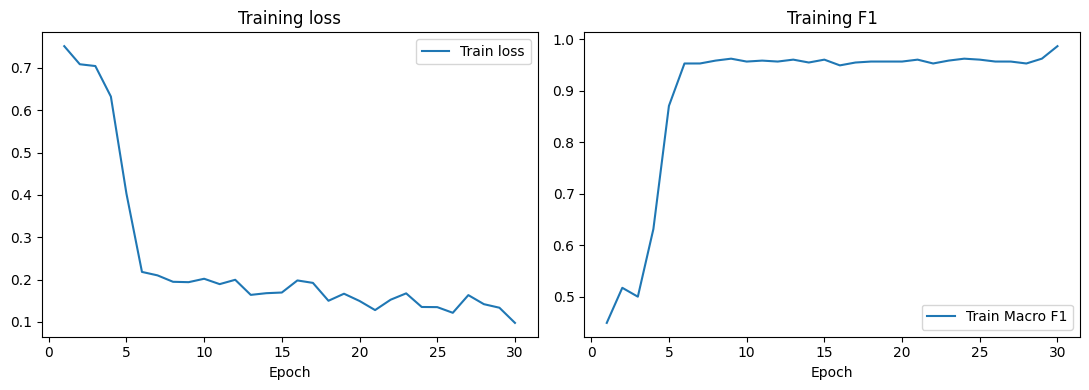

Mean seconds/epoch: 8.7
These training curves do not tell us which epoch generalizes best.


In [9]:
# 9 — Training curves (no validation curve because there is no validation split).
results = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(results.epoch, results.train_loss, label='Train loss')
axes[0].set_xlabel('Epoch'); axes[0].set_title('Training loss'); axes[0].legend()
axes[1].plot(results.epoch, results.train_f1_macro, label='Train Macro F1')
axes[1].set_xlabel('Epoch'); axes[1].set_title('Training F1'); axes[1].legend()
plt.tight_layout(); plt.show()
print('Mean seconds/epoch:', round(results.seconds.mean(), 1))
print('These training curves do not tell us which epoch generalizes best.')


### Final Test — Run once after training (V5 vs V6)
V6 uses the same train/test video hashes as V5; original V5 scores are already known. Comparison is an internal ablation, not an untouched test or proof of unseen-camera generalization.

In [10]:
# 10 — ONE final Test evaluation after 30 predetermined epochs.
# Controlled ablation against V5, NOT a fresh generalization estimate.
assert FINAL_MODEL_PATH.exists(), 'Run training before the final evaluation.'
final_ckpt = torch.load(FINAL_MODEL_PATH, map_location=DEVICE, weights_only=True)
model.load_state_dict(final_ckpt['model'], strict=True)
model.eval()
true_labels, pred_labels, probabilities = [], [], []
with torch.inference_mode():
    for clips, labels, lengths in test_loader:
        logits = model(clips.to(DEVICE), lengths)
        true_labels.extend(labels.tolist())
        pred_labels.extend(logits.argmax(1).cpu().tolist())
        probabilities.extend(torch.softmax(logits.float(), dim=1)[:, 1].cpu().tolist())

metrics = dict(
    epoch=EPOCHS, n_test=len(true_labels),
    accuracy=accuracy_score(true_labels, pred_labels),
    precision_macro=precision_score(true_labels, pred_labels, average='macro', zero_division=0),
    recall_macro=recall_score(true_labels, pred_labels, average='macro', zero_division=0),
    f1_macro=f1_score(true_labels, pred_labels, average='macro', zero_division=0),
    shoplifting_recall=recall_score(true_labels, pred_labels, pos_label=1, zero_division=0),
)
(OUT / 'final_test_metrics.json').write_text(json.dumps(metrics, indent=2))
preds_df = test_ds.rows.copy().reset_index(drop=True)
assert preds_df.label.tolist() == true_labels
preds_df['predicted'] = pred_labels
preds_df['prob_shoplifting'] = probabilities
preds_df['correct'] = preds_df.label == preds_df.predicted
preds_df.to_csv(OUT / 'final_test_predictions.csv', index=False)
print('V6 No-Attention final Test (evaluated once, AFTER training):')
print(json.dumps(metrics, indent=2))
print(classification_report(true_labels, pred_labels, labels=[0, 1],
                            target_names=['Normal', 'Shoplifting'], zero_division=0))
print('Confusion Matrix:'); print(confusion_matrix(true_labels, pred_labels, labels=[0, 1]))

# V5 vs V6 on *exactly identical* test videos (same SHA-256, labels, number).
v5_pred_path = V5_DIR / 'final_test_predictions.csv'
if v5_pred_path.is_file():
    v5_preds = pd.read_csv(v5_pred_path)
    required = {'sha256', 'label', 'predicted'}
    assert required.issubset(v5_preds.columns), 'V5 predictions missing required columns'
    assert v5_preds.sha256.is_unique and preds_df.sha256.is_unique
    assert len(v5_preds) == len(preds_df)
    assert set(v5_preds.sha256.astype(str)) == set(preds_df.sha256.astype(str)), (
        'Cannot compare: test video hashes differ'
    )
    aligned = v5_preds[['sha256', 'label', 'predicted']].merge(
        preds_df[['sha256', 'label', 'predicted']], on='sha256',
        suffixes=('_v5', '_v6'), validate='one_to_one')
    assert (aligned.label_v5 == aligned.label_v6).all()
    comparison = []
    for v in ('v5', 'v6'):
        y = aligned.label_v5.to_numpy()
        pred = aligned[f'predicted_{v}'].to_numpy()
        comparison.append(dict(
            model='Original V5 (Attention)' if v == 'v5' else 'V6 (No Attention)',
            epoch=30,
            accuracy=accuracy_score(y, pred),
            macro_f1=f1_score(y, pred, average='macro', zero_division=0),
            shoplifting_recall=recall_score(y, pred, pos_label=1, zero_division=0),
            errors=int((y != pred).sum())))
    comparison = pd.DataFrame(comparison)
    comparison.to_csv(OUT / 'V5_vs_V6_same_test.csv', index=False)
    print('\nV5 vs V6 on IDENTICAL test video hashes:')
    display(comparison)
    aligned['v5_correct'] = aligned.label_v5 == aligned.predicted_v5
    aligned['v6_correct'] = aligned.label_v6 == aligned.predicted_v6
    print('V6 fixed V5 errors:', int((~aligned.v5_correct & aligned.v6_correct).sum()))
    print('V6 newly wrong:', int((aligned.v5_correct & ~aligned.v6_correct).sum()))
    print('Changed predictions:', int((aligned.predicted_v5 != aligned.predicted_v6).sum()))
    aligned.to_csv(OUT / 'V5_vs_V6_per_video.csv', index=False)
else:
    print('V5 predictions file unavailable; V6 predictions are saved, no numeric comparison produced.')
print('Reminder: the V5 test was viewed repeatedly. This is an internal architecture comparison.')


V6 No-Attention final Test (evaluated once, AFTER training):
{
  "epoch": 30,
  "n_test": 95,
  "accuracy": 0.9578947368421052,
  "precision_macro": 0.9607843137254901,
  "recall_macro": 0.9583333333333333,
  "f1_macro": 0.9578527062999113,
  "shoplifting_recall": 0.9166666666666666
}
              precision    recall  f1-score   support

      Normal       0.92      1.00      0.96        47
 Shoplifting       1.00      0.92      0.96        48

    accuracy                           0.96        95
   macro avg       0.96      0.96      0.96        95
weighted avg       0.96      0.96      0.96        95

Confusion Matrix:
[[47  0]
 [ 4 44]]

V5 vs V6 on IDENTICAL test video hashes:


,model,epoch,accuracy,macro_f1,shoplifting_recall,errors
0,Original V5 (Attention),30,0.894737,0.894725,0.895833,10
1,V6 (No Attention),30,0.957895,0.957853,0.916667,4


V6 fixed V5 errors: 10
V6 newly wrong: 4
Changed predictions: 14
Reminder: the V5 test was viewed repeatedly. This is an internal architecture comparison.
